In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

Load the datasets.

In [26]:
# Load the California Housing Dataset
housing = fetch_california_housing()

# Convert dataser into pandas DataFrame
df = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

# Add target column
df["Price"] = housing.target

Inspect the dataset

In [27]:
# Display first five records
print(df.head())

# Dataset dimensions
print("\nDataset Shape:")
print(df.shape)

# Column names
print("\nColumn Names:")
print(df.columns)

# Dataset info
print("\nDataset information:")
df.info()

# Statistic summary
print("\nStatistic summary")
print(df.describe())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  Price  
0    -122.23  4.526  
1    -122.22  3.585  
2    -122.24  3.521  
3    -122.25  3.413  
4    -122.25  3.422  

Dataset Shape:
(20640, 9)

Column Names:
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'Price'],
      dtype='str')

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-

Check data quality

In [28]:
# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records.
print("\nDuplicate Records:")
print(df.duplicated().sum())


Missing values:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Price         0
dtype: int64

Duplicate Records:
0


Data Processing

In [51]:
# Separate input features and target variable
X = df.drop("Price", axis=1)
y = df["Price"]

# Check minimum and maximum values of each feature
print("Feature Ranges:")
print(X.describe().loc[["min", "max"]])

Feature Ranges:
      MedInc  HouseAge    AveRooms  AveBedrms  Population     AveOccup  \
min   0.4999       1.0    0.846154   0.333333         3.0     0.692308   
max  15.0001      52.0  141.909091  34.066667     35682.0  1243.333333   

     Latitude  Longitude  
min     32.54    -124.35  
max     41.95    -114.31  


## Preprocessing Summary

The dataset was examined for missing values, duplicate records, and feature ranges.

- No missing values were found.
- No duplicate records were identified.
- All input features are numerical, so categorical encoding is unnecessary.
- Feature scaling was not applied because ordinary Linear Regression does not require standardized input features.

Therefore, the dataset is suitable for training the Linear Regression model without additional transformations.

Price distribution

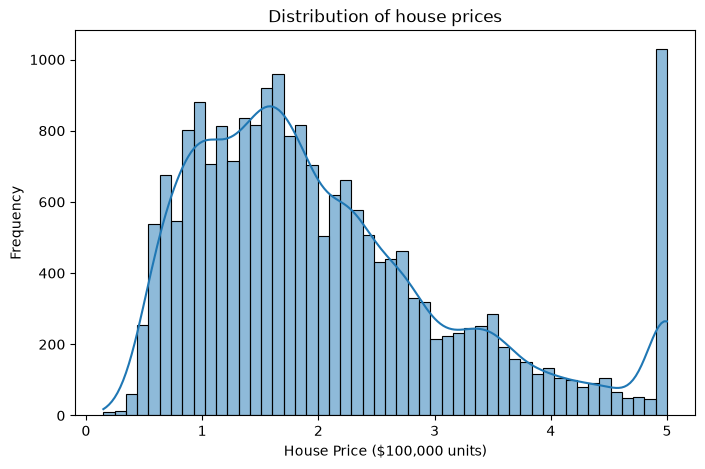

In [29]:
# graph of Frequency VS House Price
plt.figure(figsize=(8, 5))

sns.histplot(df["Price"], bins=50, kde=True)

plt.title("Distribution of house prices")
plt.xlabel("House Price ($100,000 units)")
plt.ylabel("Frequency")

plt.show()

Income VS Price

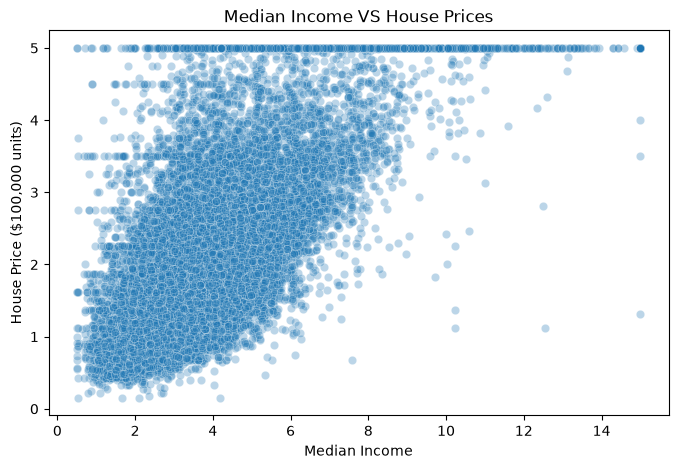

In [30]:
# Relation between median income and house prices
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="MedInc",
    y="Price",
    alpha=0.3
)
plt.title("Median Income VS House Prices")
plt.xlabel("Median Income")
plt.ylabel("House Price ($100,000 units)")

plt.show()

Correlation Heatmap

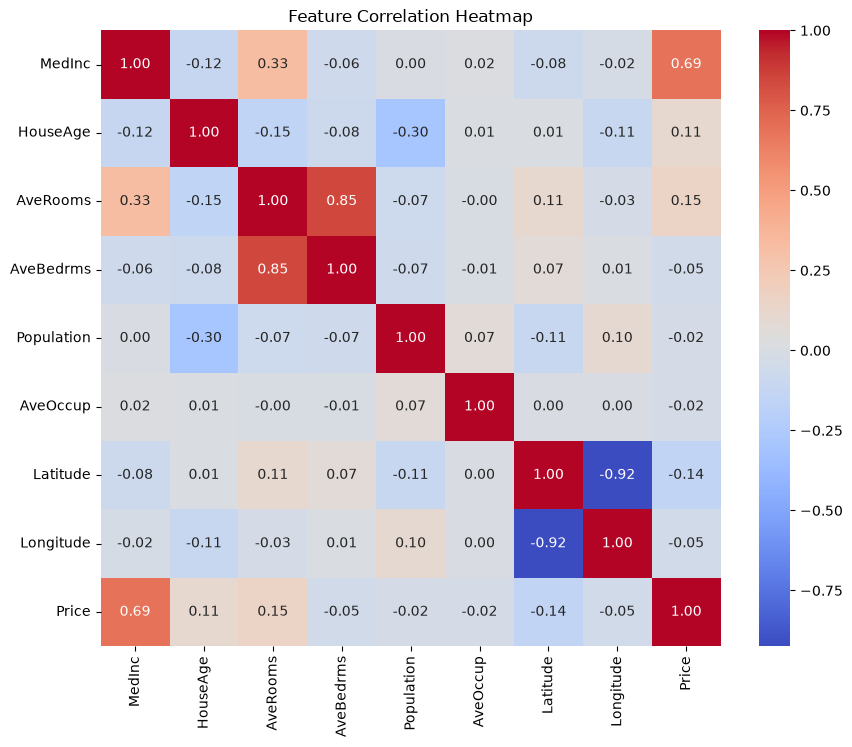

In [31]:
# Correlation Heatmap
plt.figure(figsize=(10, 8))

correlation = df.corr()

sns.heatmap(correlation,
            annot=True,
            cmap="coolwarm",
            fmt=".2f")

plt.title("Feature Correlation Heatmap")

plt.show()

Model Training

In [32]:
import pandas as pd
from IPython.core.pylabtools import figsize
from mpmath import residual

from sklearn.datasets import fetch_california_housing
from statsmodels.tsa.base import prediction

Load the datasets

In [33]:
housing = fetch_california_housing()

df = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

df["Price"] = housing.target

Seperating features(X) and Target(Y)

In [34]:
X = df.drop("Price", axis=1)
Y = df["Price"]

Test X and Y

In [35]:
print("Features shape:", X.shape)
print("Target shape:", Y.shape)

print(X.head())
print(Y.head())

Features shape: (20640, 8)
Target shape: (20640,)
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: Price, dtype: float64


Train-Test Split : we will train 80% of data and test the model on the rest 20%.

In [36]:
from sklearn.model_selection import train_test_split

In [37]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size = 0.2,
    random_state=42
)

Verification

In [38]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("Y_train:", Y_train.shape)
print("Y_test:", Y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
Y_train: (16512,)
Y_test: (4128,)


Using Linear Regression to train the model.

In [39]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 0.45, 0.01,-0.12,...,-0. ,-0.42,-0.43]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-37.02
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [40]:
print("Intercept:", model.intercept_)
print("\nCoefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

Intercept: -37.02327770606425

Coefficients:
MedInc : 0.4486749096657187
HouseAge : 0.009724257517904985
AveRooms : -0.12332334282796019
AveBedrms : 0.783144906792973
Population : -2.029620580138237e-06
AveOccup : -0.0035263184871342206
Latitude : -0.41979248658835816
Longitude : -0.43370806496398806


In [41]:
predictions = model.predict(X_test)

print(predictions[:10])

comparison = pd.DataFrame({
    "Actual Price:": Y_test.values[:10],
    "Predicted Price:": predictions[:10]
})

print(comparison)

[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]
   Actual Price:  Predicted Price:
0        0.47700          0.719123
1        0.45800          1.764017
2        5.00001          2.709659
3        2.18600          2.838926
4        2.78000          2.604657
5        1.58700          2.011754
6        1.98200          2.645500
7        1.57500          2.168755
8        3.40000          2.740746
9        4.46600          3.915615


Prediction Evaluation

In [42]:
from sklearn.metrics import(
mean_absolute_error,
mean_squared_error,
r2_score
)

import numpy as np

In [43]:
mae = mean_absolute_error(Y_test, predictions)
mse = mean_squared_error(Y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, predictions)

print(f"MAE: {mae}\nMSE: {mse}\nRMSE: {rmse}\nR2 Score: {r2}")

MAE: 0.5332001304956547
MSE: 0.5558915986952437
RMSE: 0.745581383012776
R2 Score: 0.5757877060324512


Visualize prediction accuracy

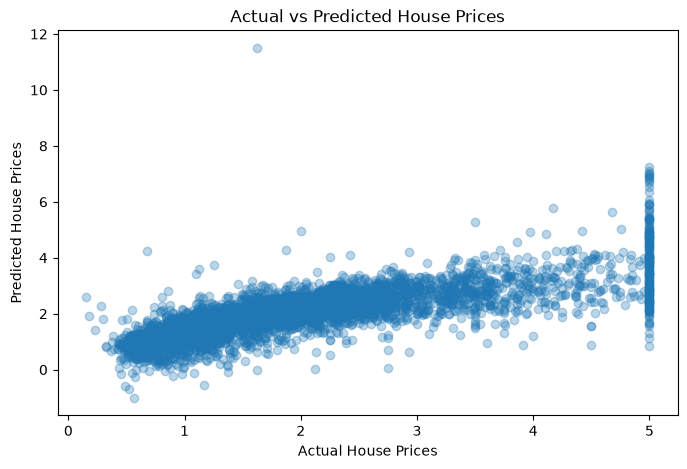

In [44]:
plt.figure(figsize=(8,5))

plt.scatter(Y_test, predictions, alpha = 0.3)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()


Residual analysis

Residual = Actual Price - Predicted Price

+ve indicates underestimated price and -ve means overestimated price

In [45]:
residuals = Y_test - predictions

print(residuals[:10])

20046   -0.242123
3024    -1.306017
15663    2.290351
20484   -0.652926
9814     0.175343
13311   -0.424754
7113    -0.663500
7668    -0.593755
18246    0.659254
5723     0.550385
Name: Price, dtype: float64


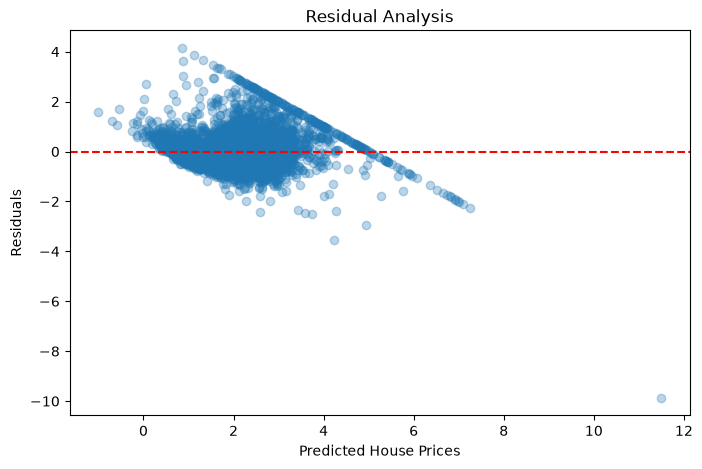

In [46]:
plt.figure(figsize=(8, 5))

plt.scatter(predictions, residuals, alpha=0.3)

plt.axhline(y = 0, color="red", linestyle="--")

plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")
plt.title("Residual Analysis")

plt.show()

Testing weather our model id underfit or overfit or a good fit by comparing training R2 vs testing R2.

In [47]:
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

train_r2 = r2_score(Y_train, train_predictions)
test_r2 = r2_score(Y_test, test_predictions)

print("Training R2:", train_r2)
print("Testing R2:", test_r2)

Training R2: 0.6125511913966952
Testing R2: 0.5757877060324512


## Conclusion

In this project, a Linear Regression model was developed using the California Housing dataset to predict house prices.

The project covered the complete machine learning workflow, including:

- Loading and exploring the dataset.
- Checking data quality, missing values and duplicate records.
- Examining preprocessing requirements.
- Splitting the dataset into training and testing sets.
- Training a Linear Regression model.
- Evaluating model performance using regression metrics.
- Analyzing actual predictions and residuals.

### Model Performance

The Linear Regression model achieved the following results:

| Evaluation Metric | Result |
|---|---:|
| Mean Absolute Error (MAE) | 0.5332 |
| Mean Squared Error (MSE) | 0.5559 |
| Root Mean Squared Error (RMSE) | 0.7456 |
| Training R² Score | 0.6126 |
| Testing R² Score | 0.5758 |

The testing R² score indicates that the model explains approximately 57.58% of the variation in house prices in the test dataset.

The model provides a baseline for house-price prediction. Its performance also indicates that additional improvements and more advanced techniques could be explored in future work.

Overall, this project provided practical experience with the end-to-end machine learning workflow using Python and Scikit-learn.